In [39]:
import os
import subprocess
import shutil
import re
import matplotlib.pyplot as plt
import numpy as np

In [40]:

def modify_config_file(config_file, signal_strength):
    """
    Modify the config file to set the signal strength
    """
    # Read the current config file
    with open(config_file, 'r') as f:
        lines = f.readlines()
    
    # Find and modify the SIGNAL_STRENGTH line, or add it if not present
    signal_line_found = False
    for i, line in enumerate(lines):
        if 'SIGNAL_STRENGTH' in line:
            lines[i] = f"SIGNAL_STRENGTH = {signal_strength}\n"
            signal_line_found = True
            break
    
    # If SIGNAL_STRENGTH line not found, add it
    if not signal_line_found:
        lines.append(f"SIGNAL_STRENGTH = {signal_strength}\n")
    
    # Write back to file
    with open(config_file, 'w') as f:
        f.writelines(lines)
    
    print(f"Updated config file with signal strength: {signal_strength}")

# Define signal strengths to test0
signal_strengths = np.linspace(0.0, 0.5, 2)  # 
num_simulations = 35
config_file = "config.txt"

# Dictionary to store results for each signal strength
results = {}

print("Running 35 simulations for each signal strength...")

# Compile the C++ code once
print("Compiling C++ code...")
compile_process = subprocess.run(["g++", "main_GRN.cpp", "-o", "main_GRN"], capture_output=True, text=True)
if compile_process.returncode != 0:
    print("Compilation failed:")
    print(compile_process.stderr)
    exit(1)
else:
    print("Compilation successful!")

for signal_idx, signal_strength in enumerate(signal_strengths):
    print(f"\n=== Processing Signal Strength: {signal_strength} ({signal_idx+1}/{len(signal_strengths)}) ===")
    
    # Modify config file for this signal strength
    modify_config_file(config_file, signal_strength)
    
    all_trajectories = []
    
    for i in range(num_simulations):
        if (i + 1) % 10 == 0:  # Print progress every 10 simulations
            print(f"  Simulation {i+1}/100 for signal {signal_strength}")
        
        # Run the C++ simulation
        run_process = subprocess.run(["./main_GRN"], capture_output=True, text=True)
        
        if run_process.returncode == 0:
            # Load the data for this simulation
            if os.path.exists('concentrations.txt'):
                data = np.loadtxt('concentrations.txt')
                all_trajectories.append(data)
            else:
                print(f"Warning: concentrations.txt not found for simulation {i+1}")
        else:
            print(f"Warning: Simulation {i+1} failed with error:")
            print(run_process.stderr)
    
    if all_trajectories:
        # Convert to numpy array
        all_trajectories = np.array(all_trajectories)
        
        # Store results
        results[signal_strength] = {
            'trajectories': all_trajectories,
            'time': all_trajectories[0, :, 0],
            'all_mRNA': all_trajectories[:, :, 1::2],
            'all_protein': all_trajectories[:, :, 2::2],
            'mean_mRNA': np.mean(all_trajectories[:, :, 1::2], axis=0),
            'mean_protein': np.mean(all_trajectories[:, :, 2::2], axis=0),
            'std_mRNA': np.std(all_trajectories[:, :, 1::2], axis=0),
            'std_protein': np.std(all_trajectories[:, :, 2::2], axis=0)
        }
        print(f"  Successfully processed {len(all_trajectories)} simulations for signal {signal_strength}")
    else:
        print(f"  No valid data found for signal {signal_strength}")

print("\nAll simulations completed!")

Running 35 simulations for each signal strength...
Compiling C++ code...
Compilation successful!

=== Processing Signal Strength: 0.0 (1/2) ===
Updated config file with signal strength: 0.0
  Simulation 10/100 for signal 0.0
  Simulation 20/100 for signal 0.0
  Simulation 30/100 for signal 0.0
  Successfully processed 35 simulations for signal 0.0

=== Processing Signal Strength: 0.5 (2/2) ===
Updated config file with signal strength: 0.5
  Simulation 10/100 for signal 0.5
  Simulation 20/100 for signal 0.5
  Simulation 30/100 for signal 0.5
  Successfully processed 35 simulations for signal 0.5

All simulations completed!


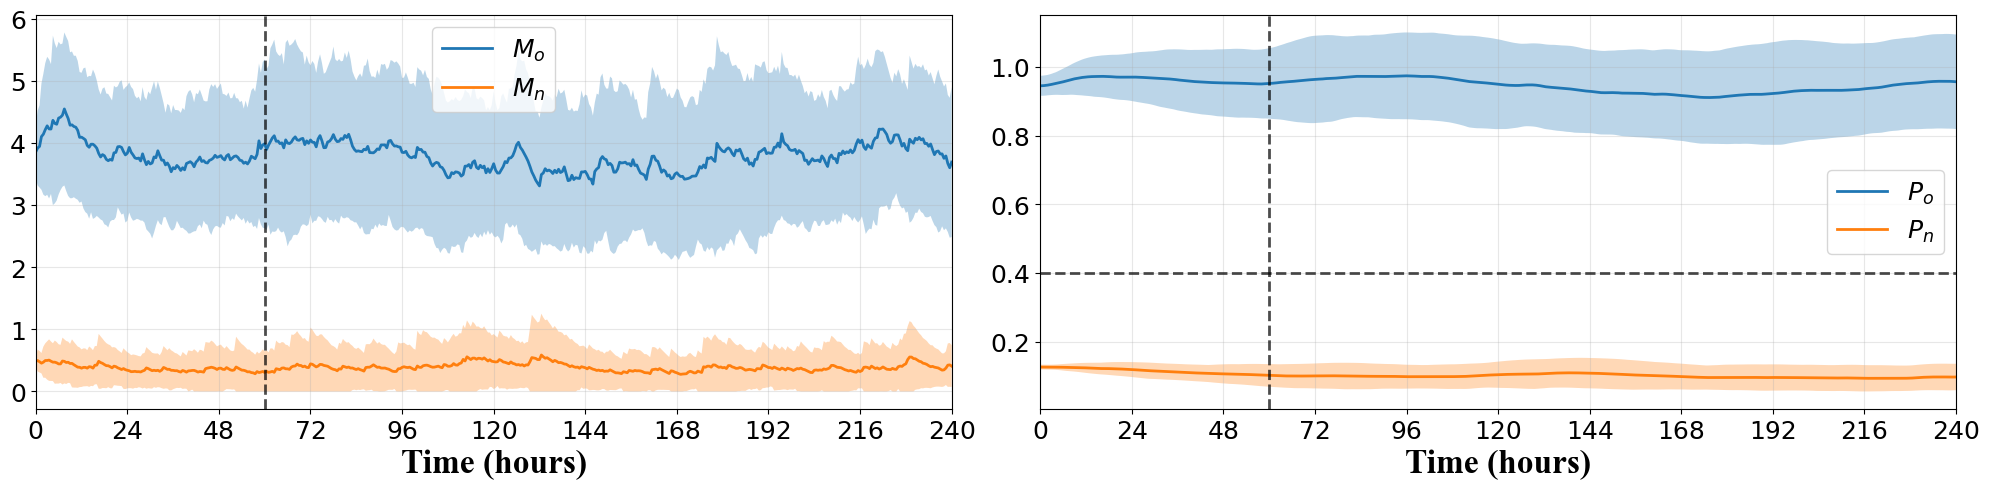

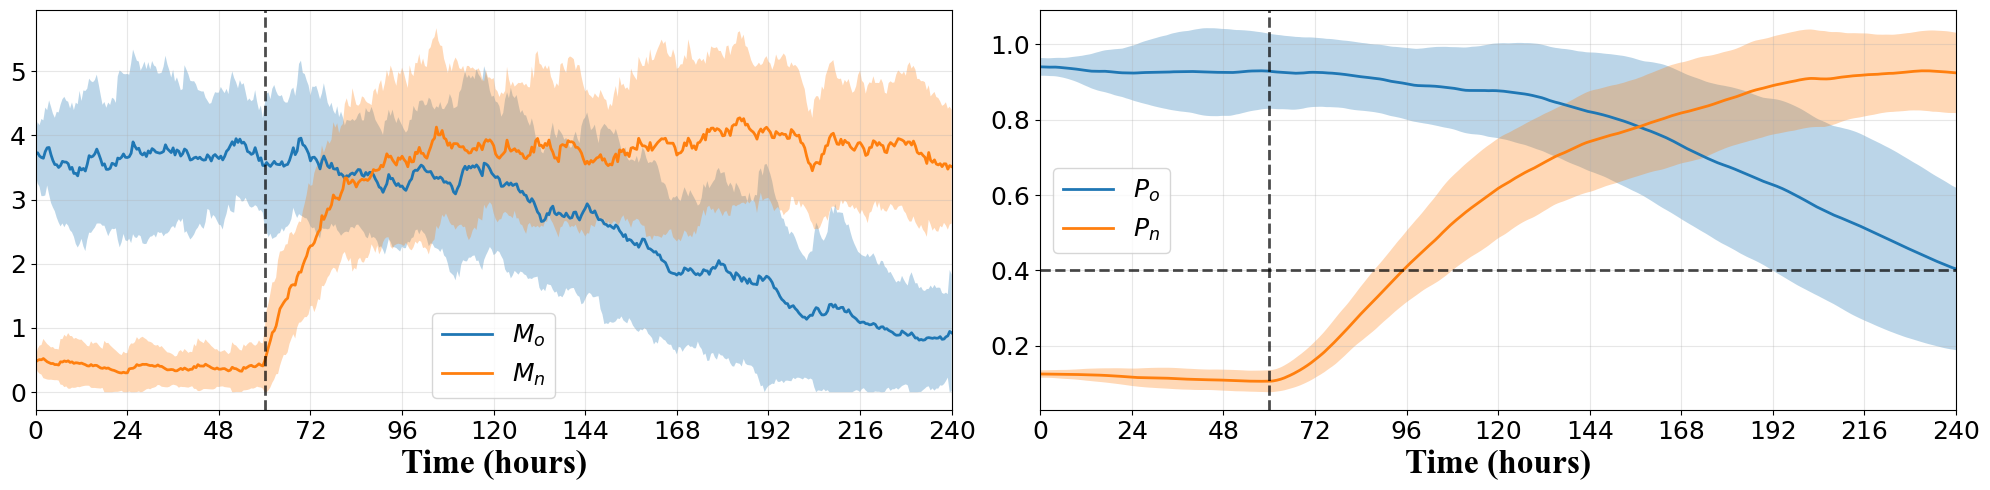

In [41]:
# Individual plots for each signal strength with error bands
# Split into multiple figures so each figure contains at most 5 signal strengths.
mRNALabels = [r'$M_o$', r'$M_n$']
ProteinLabels = [r'$P_o$', r'$P_n$']

signal_vals = list(results.keys())
plots_per_figure = 1

for batch_start in range(0, len(signal_vals), plots_per_figure):
    batch_signals = signal_vals[batch_start:batch_start + plots_per_figure]
    n_rows = len(batch_signals)

    fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows))
    if n_rows == 1:
        axes = axes.reshape(1, -1)

    for row_idx, signal_strength in enumerate(batch_signals):
        data = results[signal_strength]
        time = data['time']
        mean_mRNA = data['mean_mRNA']
        mean_protein = data['mean_protein']
        std_mRNA = data['std_mRNA']
        std_protein = data['std_protein']

        total_time = time.max()
        xticks = np.linspace(time.min(), total_time, 11)

        # Plot mRNA with error bands
        for gene_idx in range(mean_mRNA.shape[1]):
            axes[row_idx, 0].plot(time, mean_mRNA[:, gene_idx],
                                  label=mRNALabels[gene_idx], linewidth=2)

            # Add error bands (clipped to prevent negative values)
            lower_bound = np.maximum(mean_mRNA[:, gene_idx] - std_mRNA[:, gene_idx], 0)
            upper_bound = mean_mRNA[:, gene_idx] + std_mRNA[:, gene_idx]
            axes[row_idx, 0].fill_between(time, lower_bound, upper_bound, alpha=0.3)

        # Plot protein with error bands
        for gene_idx in range(mean_protein.shape[1]):
            axes[row_idx, 1].plot(time, mean_protein[:, gene_idx],
                                  label=ProteinLabels[gene_idx], linewidth=2)

            # Add error bands (clipped to prevent negative values)
            lower_bound = np.maximum(mean_protein[:, gene_idx] - std_protein[:, gene_idx], 0)
            upper_bound = mean_protein[:, gene_idx] + std_protein[:, gene_idx]
            axes[row_idx, 1].fill_between(time, lower_bound, upper_bound, alpha=0.3)

        # axes[row_idx, 0].set_title(f'mRNA with Signal Strength $S_{{nbd}}$ = {signal_strength:.2f}', fontsize=24)
        axes[row_idx, 0].set_xlabel('Time (hours)', fontsize=24, fontweight='bold', color='black', fontfamily='Times New Roman')
        axes[row_idx, 0].legend(fontsize=18)
        axes[row_idx, 0].grid(True, alpha=0.3)
        axes[row_idx, 0].axvline(x=60, color='black', linestyle='--', linewidth=2, alpha=0.7)
        axes[row_idx, 0].set_xlim(left=time.min(), right=total_time)
        axes[row_idx, 0].set_xticks(xticks)
        axes[row_idx, 0].tick_params(axis='both', labelsize=18)

        # axes[row_idx, 1].set_title(f'Protein with Signal Strength $S_{{nbd}}$ = {signal_strength:.2f}', fontsize=24)
        axes[row_idx, 1].set_xlabel('Time (hours)', fontsize=24, fontweight='bold', color='black', fontfamily='Times New Roman')
        axes[row_idx, 1].legend(fontsize=18)
        axes[row_idx, 1].grid(True, alpha=0.3)
        axes[row_idx, 1].axvline(x=60, color='black', linestyle='--', linewidth=2, alpha=0.7)
        axes[row_idx, 1].axhline(y=0.4, color='black', linestyle='--', linewidth=2, alpha=0.7)
        axes[row_idx, 1].set_xlim(left=time.min(), right=total_time)
        axes[row_idx, 1].set_xticks(xticks)
        axes[row_idx, 1].tick_params(axis='both', labelsize=18)

    fig.tight_layout()
    fig.savefig(f"Individual_Signal_Trajectories_with_ErrorBands_{batch_start // plots_per_figure + 1}.png", dpi=300, bbox_inches='tight')
    plt.show()

In [42]:
# Export mean concentrations at 32 random time points before signal to txt file
# Signal starts at time 60, so we sample from before that

# Find time points before signal (time < 60)
sample_data = results[list(results.keys())[0]]  # Use first signal strength as reference
time = sample_data['time']
before_signal_mask = (time < 60) & (time > 20)
time_before_signal = time[before_signal_mask]

# Select 32 random time points
np.random.seed(42)  # For reproducibility
random_indices = np.random.choice(len(time_before_signal), size=32, replace=False)
random_time_points = time_before_signal[random_indices]
random_indices_sorted = np.sort(random_indices)
random_time_points_sorted = time_before_signal[random_indices_sorted]

# Prepare data for export
export_data = []

for signal_strength, data in results.items():
    mean_mRNA = data['mean_mRNA']
    mean_protein = data['mean_protein']
    
    # Extract data at random time points (before signal)
    selected_mRNA = mean_mRNA[random_indices_sorted]
    selected_protein = mean_protein[random_indices_sorted]
    
    # Create filename for this signal strength
    filename = f"mean_concentrations_signal_{signal_strength:.1f}.txt"
    
    # Write to file
    with open(filename, 'w') as f:
        f.write("Time mRNA_0 Protein_0 mRNA_1 Protein_1\n")
        for i in range(len(random_time_points_sorted)):
            line = f"{random_time_points_sorted[i]:.6f} {selected_mRNA[i,0]:.6f} {selected_protein[i,0]:.6f} {selected_mRNA[i,1]:.6f} {selected_protein[i,1]:.6f}\n"
            f.write(line)
    
    print(f"Exported data for signal strength {signal_strength} to {filename}")

print(f"\nExported mean concentrations at {len(random_time_points_sorted)} random time points before signal (t < 60)")
print(f"Random time points range: {random_time_points_sorted[0]:.2f} to {random_time_points_sorted[-1]:.2f}")

Exported data for signal strength 0.0 to mean_concentrations_signal_0.0.txt
Exported data for signal strength 0.5 to mean_concentrations_signal_0.5.txt

Exported mean concentrations at 32 random time points before signal (t < 60)
Random time points range: 20.50 to 59.50
